In [6]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.pipeline import Pipeline

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set_theme(style="whitegrid")

# Load dataset
PATH = "../../statsbomb_pipeline/data/processed/team/team_season.csv"
df = pd.read_csv(PATH)

# -------------------------
# Create 3-class xG target
# -------------------------

q1 = df["xg_for"].quantile(0.33)
q2 = df["xg_for"].quantile(0.66)

def categorize_xg(x):
    if x <= q1:
        return 0   # Low xG
    elif x <= q2:
        return 1   # Medium xG
    else:
        return 2   # High xG

df["xg_class"] = df["xg_for"].apply(categorize_xg)

print("Class distribution:")
display(df["xg_class"].value_counts())


Class distribution:


xg_class
2    7
0    7
1    6
Name: count, dtype: int64

In [7]:
# All numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Remove columns we cannot use as predictors
drop_cols = [
    "team_id",
    "matches_played",
    "wins",
    "losses",
    "draws",
    "xg_for",      # MUST drop continuous version of target
    "xg_class",    # MUST drop classification target
]

predictor_cols = [c for c in numeric_cols if c not in drop_cols]

print("Predictors used:", predictor_cols)

X = df[predictor_cols]
y = df["xg_class"]

# Stratified split to ensure all 3 classes appear in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])


Predictors used: ['goals_for', 'goals_against', 'shots_for', 'passes_for', 'carries_for', 'ppa_for', 'f3_entries_for', 'xthreat_for', 'goal_diff', 'xg_per_match', 'xthreat_per_match', 'goals_per_match', 'ppa_per_match', 'f3_entries_per_match']
Train size: 16
Test size: 4



=== KNN RESULTS ===
Accuracy: 0.5
              precision    recall  f1-score   support

      Low xG       0.50      0.50      0.50         2
   Medium xG       0.00      0.00      0.00         1
     High xG       1.00      1.00      1.00         1

    accuracy                           0.50         4
   macro avg       0.50      0.50      0.50         4
weighted avg       0.50      0.50      0.50         4



<Figure size 600x500 with 0 Axes>

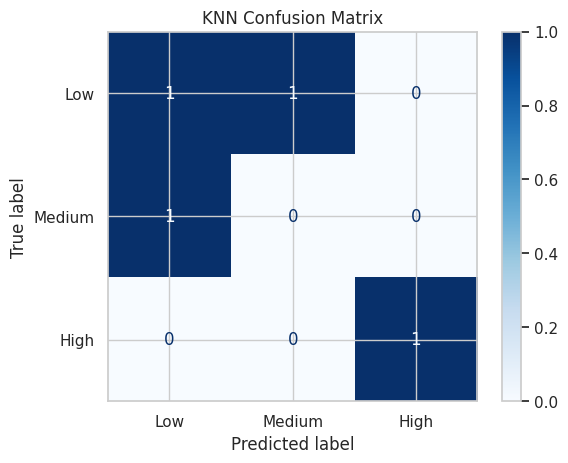

In [8]:
# -------------------------
# KNN CLASSIFIER
# -------------------------

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])

knn_pipeline.fit(X_train, y_train)
y_pred_knn = knn_pipeline.predict(X_test)

print("\n=== KNN RESULTS ===")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(
    y_test, y_pred_knn,
    target_names=["Low xG", "Medium xG", "High xG"]
))

# Confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(cm_knn, display_labels=["Low", "Medium", "High"])

plt.figure(figsize=(6, 5))
disp_knn.plot(cmap="Blues", values_format="d")
plt.title("KNN Confusion Matrix")
plt.show()



=== DECISION TREE RESULTS ===
Accuracy: 1.0
              precision    recall  f1-score   support

      Low xG       1.00      1.00      1.00         2
   Medium xG       1.00      1.00      1.00         1
     High xG       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



<Figure size 600x500 with 0 Axes>

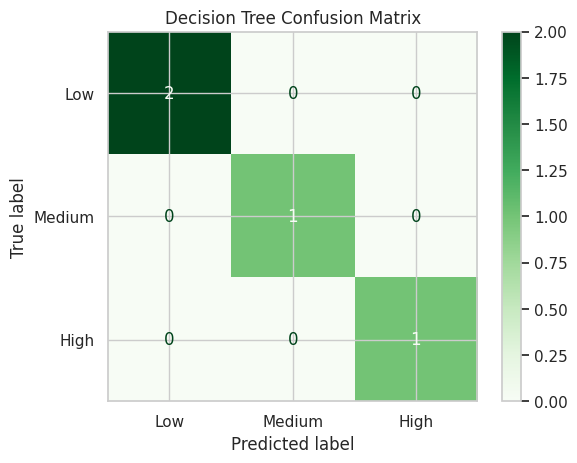

In [10]:
# -------------------------
# DECISION TREE CLASSIFIER
# -------------------------

dt_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)

print("\n=== DECISION TREE RESULTS ===")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(
    y_test, y_pred_dt,
    target_names=["Low xG", "Medium xG", "High xG"]
))

# Confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(cm_dt, display_labels=["Low", "Medium", "High"])

plt.figure(figsize=(6, 5))
disp_dt.plot(cmap="Greens", values_format="d")
plt.title("Decision Tree Confusion Matrix")
plt.show()
